# CorrDiff - Fase 5 - Sazonalidade

Análise de cobertura observacional e frequência de eventos condicionada à disponibilidade.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path('../analysis_outputs/05_seasonality')
summary = json.loads((OUT/'analysis_summary.json').read_text())
summary


{'phase_version': 'phase5-seasonality-v1-availability-conditioned',
 'dataset_patches': 1016208,
 'available_unique_timestamps': 84684,
 'expected_timestamps': 122736,
 'temporal_coverage_ratio': 0.6899687133359406,
 'period_start': '2011-01-01 00:00:00',
 'period_end': '2024-12-31 23:00:00',
 'time_frequency': '1h',
 'patches_per_timestamp_min': 12,
 'patches_per_timestamp_median': 12.0,
 'patches_per_timestamp_max': 12,
 'season_definition': {'DJF': 'DJF_verao',
  'MAM': 'MAM_outono',
  'JJA': 'JJA_inverno',
  'SON': 'SON_primavera'},
 'seasonal_climatology_complete_season_years_only': True,
 'fixed_threshold_comparison_domain': 'stored_log1p_float32',
 'radar_continuous_domain': 'expm1(stored_target): post-clip numerical radar-legend values; physical unit not assumed',
 'predictor_seasonality_computed': True,
 'monthly_lowest_coverage': [{'month': 8,
   'expected_timestamps': 10416,
   'available_timestamps': 5603,
   'missing_timestamps': 4813,
   'coverage_ratio': 0.53792242703533

## Cobertura mensal

,month,expected_timestamps,available_timestamps,missing_timestamps,coverage_ratio
0,1,10416,6867,3549,0.659274
1,2,9504,7087,2417,0.745686
2,3,10416,7628,2788,0.732335
3,4,10080,7263,2817,0.720536
4,5,10416,7664,2752,0.735791
5,6,10080,6473,3607,0.642163
6,7,10416,5758,4658,0.552803
7,8,10416,5603,4813,0.537922
8,9,10080,6601,3479,0.654861
9,10,10416,8194,2222,0.786674


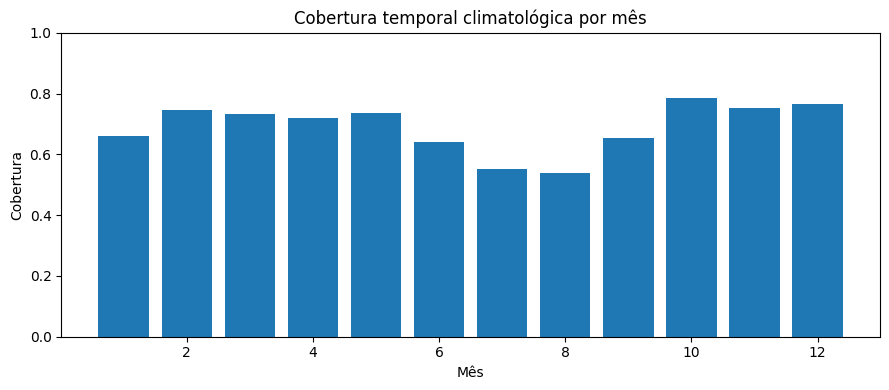

In [2]:
coverage = pd.read_parquet(OUT/'monthly_coverage.parquet')
display(coverage)
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(coverage.month, coverage.coverage_ratio)
ax.set_xlabel('Mês')
ax.set_ylabel('Cobertura')
ax.set_ylim(0,1)
ax.set_title('Cobertura temporal climatológica por mês')
plt.tight_layout()
plt.show()


## Frequência mensal condicionada à disponibilidade

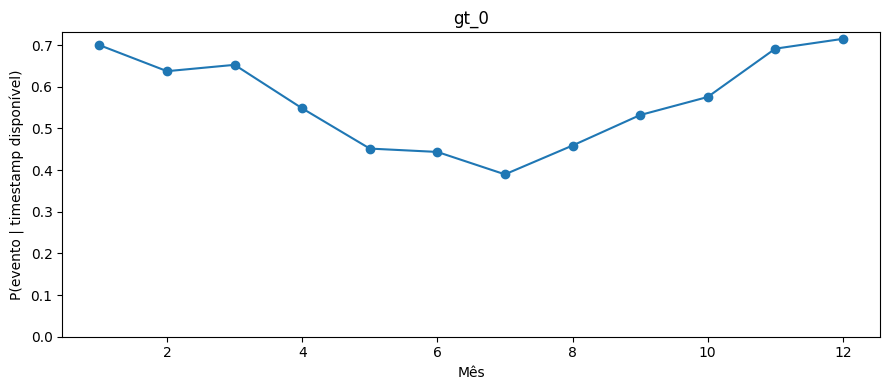

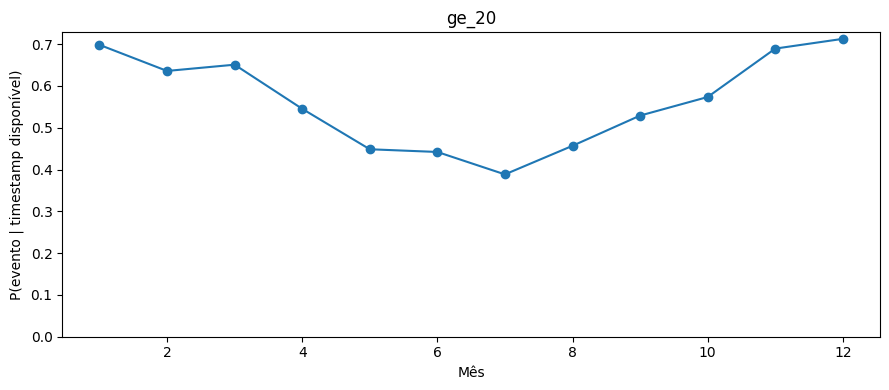

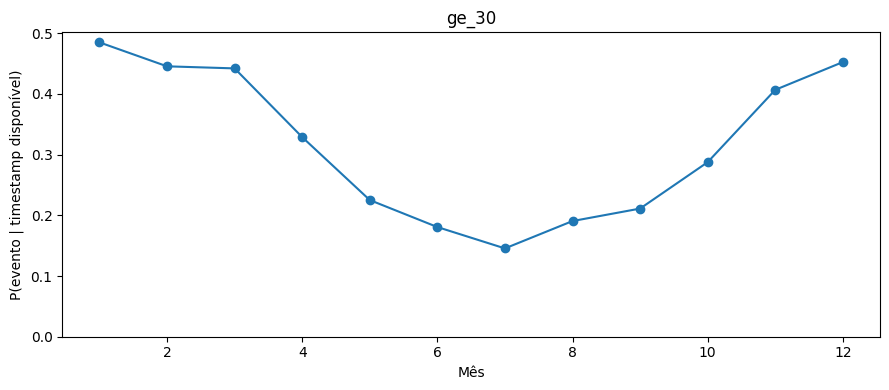

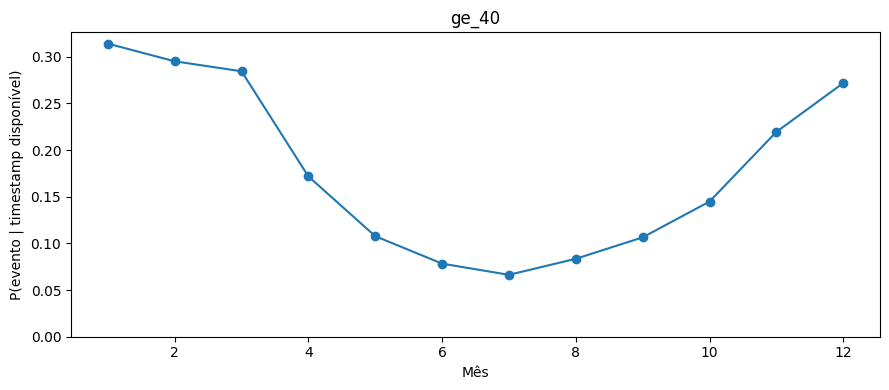

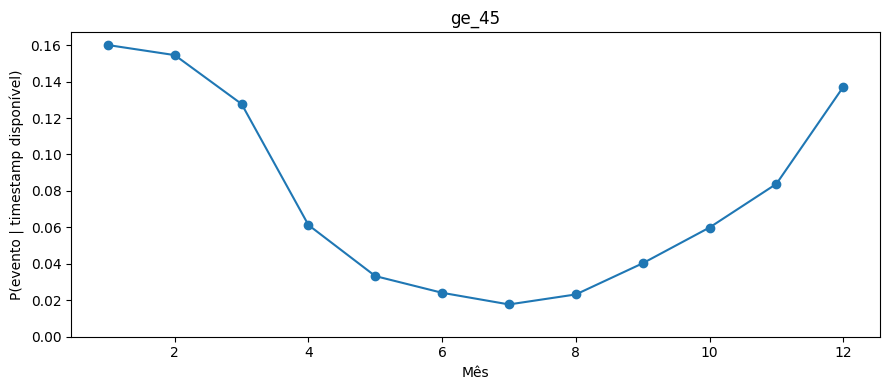

In [3]:
events = pd.read_parquet(OUT/'monthly_event_rates.parquet')
for event_id in ['gt_0','ge_20','ge_30','ge_40','ge_45']:
    t = events[events.event_id.eq(event_id)]
    fig, ax = plt.subplots(figsize=(9,4))
    ax.plot(t.month, t.timestamp_any_event_rate, marker='o')
    ax.set_xlabel('Mês')
    ax.set_ylabel('P(evento | timestamp disponível)')
    ax.set_title(event_id)
    ax.set_ylim(bottom=0)
    plt.tight_layout()
    plt.show()


## Estações do Hemisfério Sul

In [4]:
seasonal = pd.read_parquet(OUT/'seasonal_event_rates.parquet')
display(seasonal[seasonal.event_id.isin(['gt_0','ge_30','ge_40','ge_45'])])


,season_code,season,available_timestamps,valid_pixels,positive_pixels,positive_pixel_rate,timestamp_any_positive_rate,mean_positive_radar,mean_timestamp_max_radar,median_timestamp_max_radar,event_id,threshold,pixel_event_rate,timestamp_any_event_rate,patch_any_event_rate,expected_timestamps,coverage_ratio
0,DJF,DJF_verao,21153,259928064,5651144,0.021741,0.687184,26.163625,23.430321,26.055109,gt_0,0.0,0.021741,0.687184,0.382180,28176,0.750745
3,DJF,DJF_verao,21153,259928064,5651144,0.021741,0.687184,26.163625,23.430321,26.055109,ge_30,30.0,0.006630,0.461022,0.231949,28176,0.750745
5,DJF,DJF_verao,21153,259928064,5651144,0.021741,0.687184,26.163625,23.430321,26.055109,ge_40,40.0,0.001460,0.293481,0.123599,28176,0.750745
6,DJF,DJF_verao,21153,259928064,5651144,0.021741,0.687184,26.163625,23.430321,26.055109,ge_45,45.0,0.000436,0.149908,0.052609,28176,0.750745
7,JJA,JJA_inverno,17834,219144192,1492610,0.006811,0.430975,28.186216,12.188421,0.000000,gt_0,0.0,0.006811,0.430975,0.201198,30912,0.576928
10,JJA,JJA_inverno,17834,219144192,1492610,0.006811,0.430975,28.186216,12.188421,0.000000,ge_30,30.0,0.002580,0.172480,0.081590,30912,0.576928
12,JJA,JJA_inverno,17834,219144192,1492610,0.006811,0.430975,28.186216,12.188421,0.000000,ge_40,40.0,0.000801,0.076091,0.030826,30912,0.576928
13,JJA,JJA_inverno,17834,219144192,1492610,0.006811,0.430975,28.186216,12.188421,0.000000,ge_45,45.0,0.000558,0.021756,0.008023,30912,0.576928
14,MAM,MAM_outono,22555,277155840,3349818,0.012086,0.550654,27.439984,17.775246,20.000002,gt_0,0.0,0.012086,0.550654,0.290893,30912,0.729652
17,MAM,MAM_outono,22555,277155840,3349818,0.012086,0.550654,27.439984,17.775246,20.000002,ge_30,30.0,0.004351,0.331988,0.165529,30912,0.729652


## Preditores atmosféricos

In [5]:
pred_path = OUT/'monthly_predictor_statistics.parquet'
if pred_path.exists():
    pred = pd.read_parquet(pred_path)
    key = ['tcwv','r_500','t_850','t_500','v_500','r_850']
    display(pred[pred.predictor.isin(key)])


,month,predictor,source,unit,available_timestamps,mean,std,p10,median,p90
0,1,tcwv,raw,kg m^-2,6867,44.360519,8.457494,32.760792,45.206136,54.506851
4,1,t_850,raw,K,6867,291.312846,2.104016,288.256969,291.481605,293.917064
5,1,r_850,raw,%,6867,74.273255,13.052418,57.338703,73.919486,92.185718
8,1,t_500,raw,K,6867,266.888880,1.373492,264.918373,266.986236,268.558407
9,1,r_500,raw,%,6867,45.406394,31.612148,7.827328,38.098667,92.327628
...,...,...,...,...,...,...,...,...,...,...
224,12,t_850,raw,K,7961,290.544583,2.585460,286.952538,290.840761,293.653570
225,12,r_850,raw,%,7961,76.300812,14.180746,57.896044,77.469000,94.057910
228,12,t_500,raw,K,7961,266.535754,1.522010,264.662093,266.629587,268.360466
229,12,r_500,raw,%,7961,46.999195,32.304376,5.457411,45.205771,91.133383


## Nota metodológica

As frequências devem ser interpretadas condicionadas à disponibilidade observacional. As taxas pixel-a-pixel continuam representando a distribuição em patches sobrepostos.